# Filter Domain Spasial: Sharpening

## Bagian 1: Import Library


In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
os.makedirs('hasil_output', exist_ok=True)


## Bagian 2 — Load dan Praproses Citra

Citra yang digunakan: **`assets/sample_banana.jpg`** — 300×300px.  
Sharpening bekerja dengan memperkuat komponen **frekuensi tinggi** (tepi & detail).  
Citra pisang cocok karena memiliki tepi jelas antara pisang dan background.


In [2]:
img_paths = ['assets/sample_banana.jpg', '../assets/sample_banana.jpg', 'sample_banana.jpg']
img_color = None
for p in img_paths:
    if os.path.exists(p):
        img_color = cv2.imread(p)
        break

if img_color is None:
    raise FileNotFoundError("sample_banana.jpg tidak ditemukan")

img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)

print(f"Resolusi: {img_gray.shape}, min: {img_gray.min()}, mean: {img_gray.mean():.1f}, max: {img_gray.max()}")


Resolusi: (300, 300), min: 10, mean: 141.0, max: 226


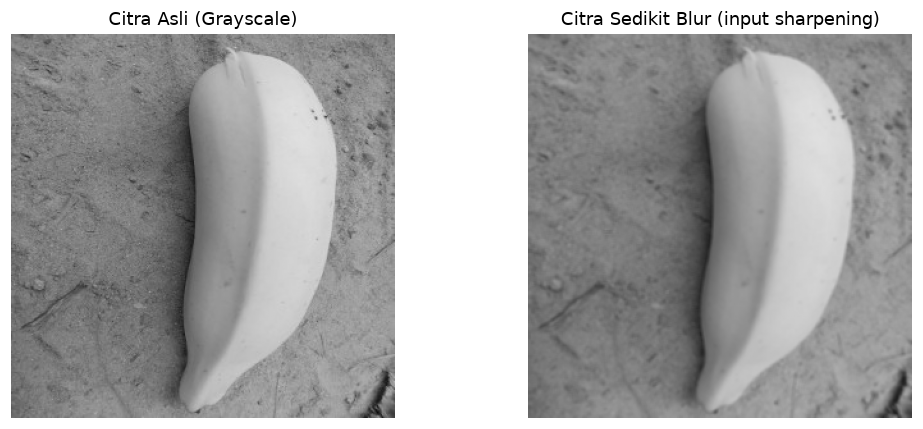

In [3]:
# Buat citra sedikit blur sebagai input yang lebih realistis untuk sharpening
kernel_blur = np.ones((3,3), dtype=np.float64) / 9.0
img_blur = cv2.blur(img_gray, (3, 3))  # sedikit blur sebagai baseline

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Citra Asli (Grayscale)')
axes[0].axis('off')
axes[1].imshow(img_blur, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Citra Sedikit Blur (input sharpening)')
axes[1].axis('off')
plt.tight_layout()
plt.show()


## Bagian 3 — Implementasi Konvolusi Manual

Fungsi konvolusi 2D diimplementasikan manual (tanpa `cv2.filter2D()`) menggunakan sliding window.

$$g(x, y) = \sum_{i=-k}^{k} \sum_{j=-k}^{k} h(i,j) \cdot f(x+i, y+j)$$

> **Catatan penting:** Hasil sharpening kemungkinan menghasilkan nilai negatif atau >255.  
> Nilai di-clip ke range [0, 255] untuk representasi citra 8-bit.


In [4]:
def konvolusi_manual(citra, kernel, padding_mode='reflect'):
    """Konvolusi 2D manual dengan clipping ke uint8 [0, 255]."""
    H, W = citra.shape
    kH, kW = kernel.shape
    pad_h = kH // 2
    pad_w = kW // 2

    citra_pad = np.pad(citra.astype(np.float64), ((pad_h, pad_h), (pad_w, pad_w)), mode=padding_mode)
    output = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            region = citra_pad[i:i + kH, j:j + kW]
            output[i, j] = np.sum(region * kernel)

    return np.clip(output, 0, 255).astype(np.uint8)


def konvolusi_float(citra, kernel, padding_mode='reflect'):
    """Konvolusi 2D manual tanpa clipping (float64) untuk intermediate step."""
    H, W = citra.shape
    kH, kW = kernel.shape
    pad_h = kH // 2
    pad_w = kW // 2

    citra_pad = np.pad(citra.astype(np.float64), ((pad_h, pad_h), (pad_w, pad_w)), mode=padding_mode)
    output = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            region = citra_pad[i:i + kH, j:j + kW]
            output[i, j] = np.sum(region * kernel)

    return output


## Bagian 4 — Laplacian Filter (Turunan Kedua)

**Laplacian** adalah operator turunan kedua 2D yang sensitif terhadap detail halus dan tepi citra.

### Definisi Laplacian 2D:

$$\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2}$$

Secara diskrit:
- Turunan ke-2 arah x: $f(x+1,y) + f(x-1,y) - 2f(x,y)$
- Turunan ke-2 arah y: $f(x,y+1) + f(x,y-1) - 2f(x,y)$

### Kernel Laplacian Dasar (4-tetangga):

$$H_{Lap} = \begin{bmatrix} 0 & 1 & 0 \\ 1 & -4 & 1 \\ 0 & 1 & 0 \end{bmatrix}$$

### Penajaman dengan Laplacian:

$$g(x,y) = f(x,y) + c \cdot \nabla^2 f(x,y)$$

Jika $c = -1$ (menggunakan kernel Laplacian dengan pusat negatif):  
$$g(x,y) = f(x,y) - \nabla^2 f(x,y)$$


In [5]:
kernel_laplacian_basic = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float64)

kernel_laplacian_diag = np.array([
    [1,  1, 1],
    [1, -8, 1],
    [1,  1, 1]
], dtype=np.float64)

kernel_sharpen_4nb = np.array([
    [0, -1,  0],
    [-1, 5, -1],
    [0, -1,  0]
], dtype=np.float64)

kernel_sharpen_8nb = np.array([
    [-1, -1, -1],
    [-1,  9, -1],
    [-1, -1, -1]
], dtype=np.float64)

print("Kernel Laplacian 4-tetangga:\n", kernel_laplacian_basic)
print("\nKernel Sharpen 4-tetangga (All-in-One):\n", kernel_sharpen_4nb)


Kernel Laplacian 4-tetangga:
 [[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]

Kernel Sharpen 4-tetangga (All-in-One):
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


In [6]:
laplacian_result = konvolusi_float(img_gray, kernel_laplacian_basic)
laplacian_vis = laplacian_result - laplacian_result.min()
laplacian_vis = (laplacian_vis / laplacian_vis.max() * 255).astype(np.uint8)

print(f"Laplacian float range: [{laplacian_result.min():.1f}, {laplacian_result.max():.1f}]")


Laplacian float range: [-197.0, 262.0]


In [7]:
img_f = img_gray.astype(np.float64)
img_sharpened_lap_4nb = np.clip(img_f - laplacian_result, 0, 255).astype(np.uint8)

img_sharpened_aio_4nb = konvolusi_manual(img_gray, kernel_sharpen_4nb)
img_sharpened_aio_8nb = konvolusi_manual(img_gray, kernel_sharpen_8nb)

mad_check = np.abs(img_sharpened_lap_4nb.astype(int) - img_sharpened_aio_4nb.astype(int)).mean()
print(f"MAD step-by-step vs all-in-one kernel: {mad_check:.4f}")


MAD step-by-step vs all-in-one kernel: 0.0000


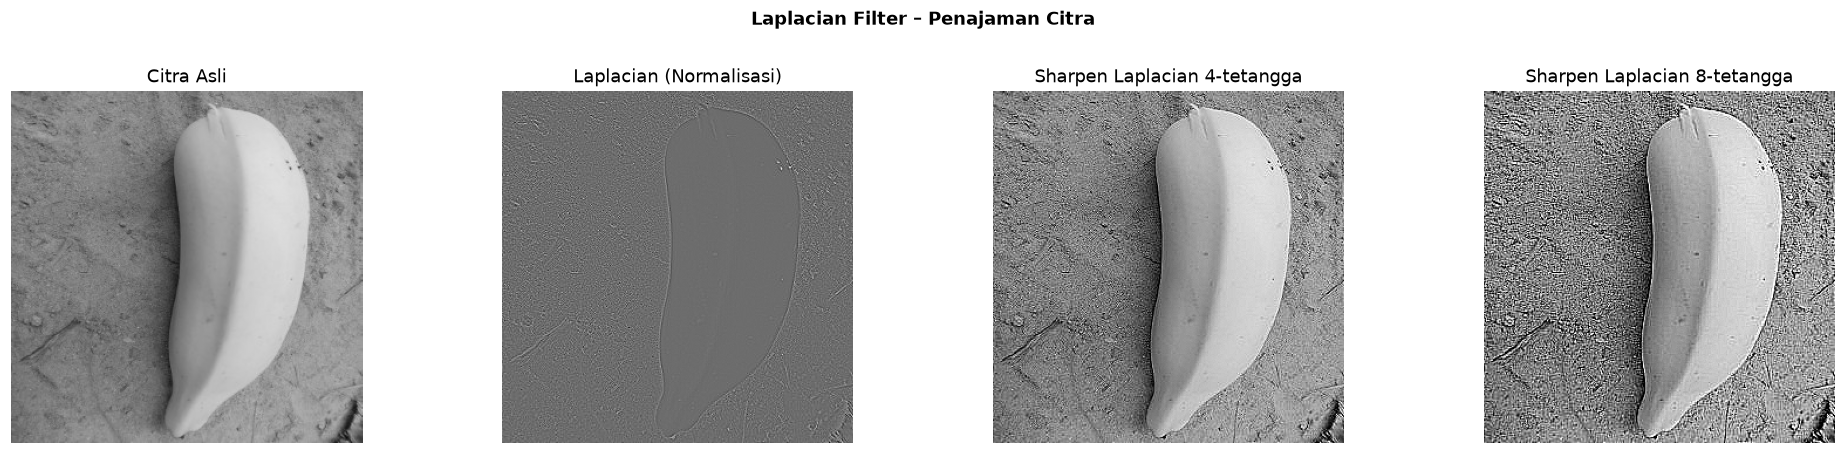

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Citra Asli')
axes[0].axis('off')

axes[1].imshow(laplacian_vis, cmap='gray')
axes[1].set_title('Laplacian (Normalisasi)')
axes[1].axis('off')

axes[2].imshow(img_sharpened_aio_4nb, cmap='gray', vmin=0, vmax=255)
axes[2].set_title('Sharpen Laplacian 4-tetangga')
axes[2].axis('off')

axes[3].imshow(img_sharpened_aio_8nb, cmap='gray', vmin=0, vmax=255)
axes[3].set_title('Sharpen Laplacian 8-tetangga')
axes[3].axis('off')

plt.suptitle('Laplacian Filter – Penajaman Citra', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Bagian 5 — Unsharp Masking

**Unsharp masking** menghasilkan citra tajam dengan cara **mengurangi versi blur** dari citra asli.

### Langkah-langkah:
1. Buat **citra lowpass** (blur menggunakan Gaussian filter)
2. Hitung **highpass** = citra asli − citra lowpass
3. Tambahkan highpass ke citra asli:

$$g(x,y) = f(x,y) + (f(x,y) - f_{lowpass}(x,y))$$

$$g(x,y) = 2f(x,y) - f_{lowpass}(x,y)$$


In [9]:
def buat_kernel_gaussian(ukuran, sigma):
    k = ukuran // 2
    xs = np.arange(-k, k + 1, dtype=np.float64)
    ys = np.arange(-k, k + 1, dtype=np.float64)
    X, Y = np.meshgrid(xs, ys)
    G = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
    return G / G.sum()

kernel_gauss = buat_kernel_gaussian(5, sigma=1.5)
img_lowpass = konvolusi_float(img_gray, kernel_gauss)
img_highpass = img_gray.astype(np.float64) - img_lowpass

hp_vis = img_highpass - img_highpass.min()
hp_vis = (hp_vis / hp_vis.max() * 255).astype(np.uint8)

print(f"Lowpass range: [{img_lowpass.min():.1f}, {img_lowpass.max():.1f}], Highpass range: [{img_highpass.min():.1f}, {img_highpass.max():.1f}]")


Lowpass range: [37.6, 223.6], Highpass range: [-88.9, 52.5]


In [10]:
img_unsharp = img_gray.astype(np.float64) + img_highpass
img_unsharp = np.clip(img_unsharp, 0, 255).astype(np.uint8)

print(f"Unsharp masking range: [{img_unsharp.min()}, {img_unsharp.max()}]")


Unsharp masking range: [0, 250]


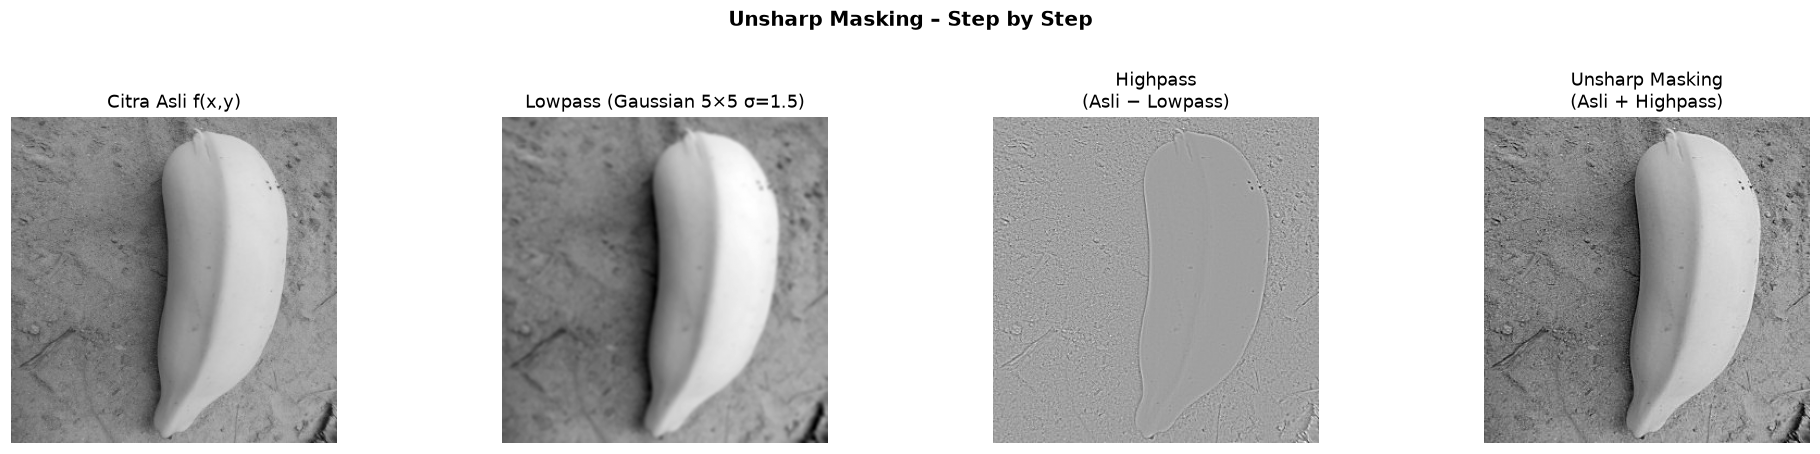

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Citra Asli f(x,y)')
axes[0].axis('off')

axes[1].imshow(np.clip(img_lowpass, 0, 255).astype(np.uint8), cmap='gray')
axes[1].set_title('Lowpass (Gaussian 5×5 σ=1.5)')
axes[1].axis('off')

axes[2].imshow(hp_vis, cmap='gray')
axes[2].set_title('Highpass\n(Asli − Lowpass)')
axes[2].axis('off')

axes[3].imshow(img_unsharp, cmap='gray', vmin=0, vmax=255)
axes[3].set_title('Unsharp Masking\n(Asli + Highpass)')
axes[3].axis('off')

plt.suptitle('Unsharp Masking – Step by Step', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Bagian 6 — High Boost Filter

**High Boost filter** adalah generalisasi dari Unsharp Masking dengan parameter **α** yang mengontrol seberapa kuat citra asli dikuatkan.

### Rumus:

$$\text{Highboost} = \alpha \cdot f(x,y) - f_{lowpass}(x,y)$$

$$= (\alpha - 1) \cdot f(x,y) + \underbrace{(f(x,y) - f_{lowpass}(x,y))}_{\text{highpass}}$$

- Jika $\alpha = 1$ → sama dengan Unsharp Masking
- Jika $\alpha > 1$ → bagian dari citra asli dikembalikan ke hasil highpass (lebih terang dan tajam)
- Jika $\alpha < 1$ → citra lebih gelap tapi tetap tajam


In [12]:
def high_boost_filter(citra_asli, lowpass_img, alpha):
    f = citra_asli.astype(np.float64)
    result = alpha * f - lowpass_img
    return np.clip(result, 0, 255).astype(np.uint8)

alphas = [0.5, 1.0, 1.5, 2.5, 6.5]
hasil_highboost = {}
for a in alphas:
    hasil_highboost[a] = high_boost_filter(img_gray, img_lowpass, alpha=a)
    print(f"alpha={a:<4.1f} -> range: [{hasil_highboost[a].min():>3}, {hasil_highboost[a].max():>3}], mean: {hasil_highboost[a].mean():.1f}")


alpha=0.5  -> range: [  0,   0], mean: 0.0
alpha=1.0  -> range: [  0,  52], mean: 1.9
alpha=1.5  -> range: [  0, 150], mean: 70.0
alpha=2.5  -> range: [  0, 255], mean: 203.0
alpha=6.5  -> range: [ 24, 255], mean: 254.7


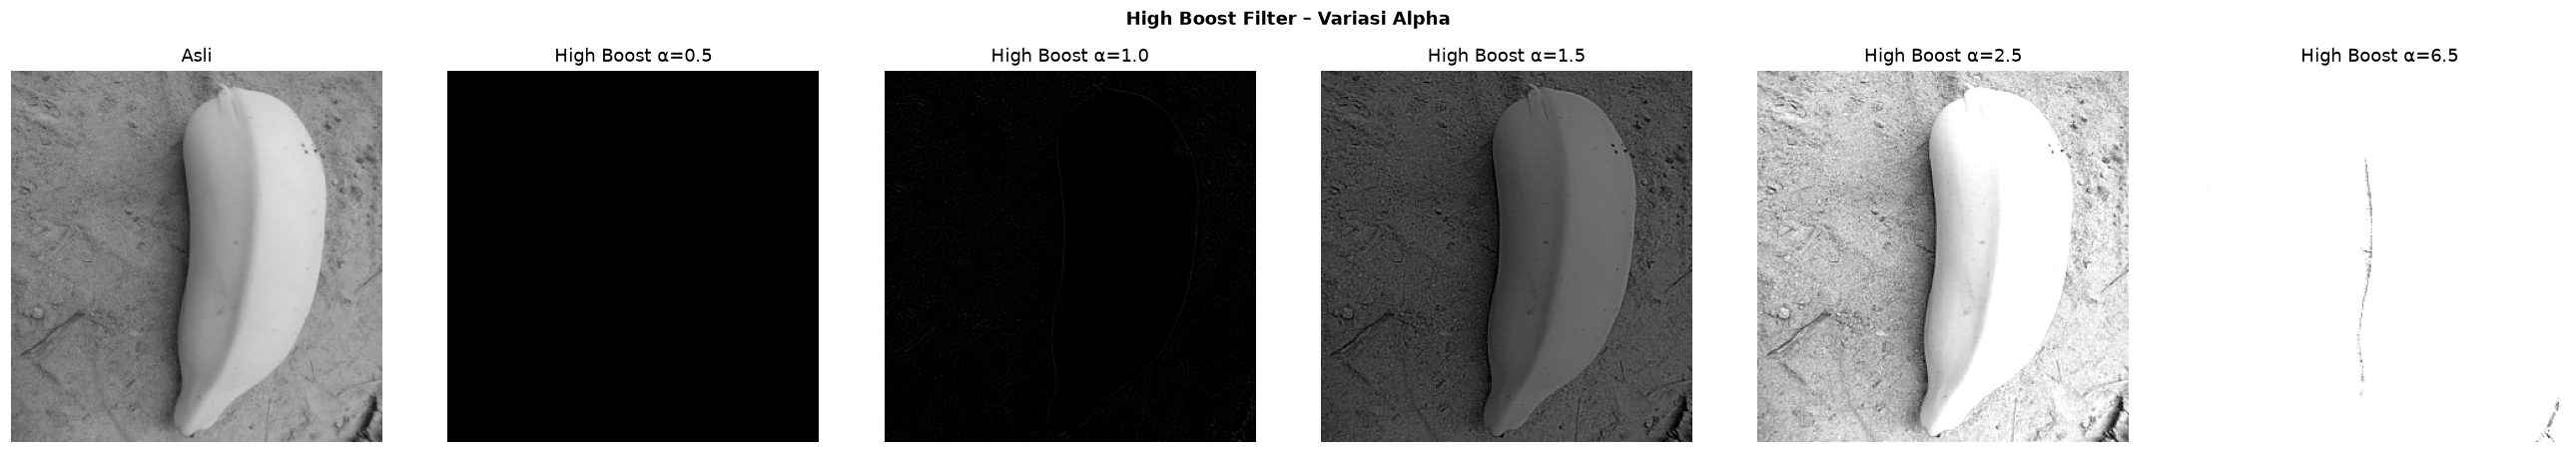

In [13]:
fig, axes = plt.subplots(1, len(alphas)+1, figsize=(4*(len(alphas)+1), 4))

axes[0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Asli')
axes[0].axis('off')

for ax, a in zip(axes[1:], alphas):
    ax.imshow(hasil_highboost[a], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'High Boost α={a}')
    ax.axis('off')

plt.suptitle('High Boost Filter – Variasi Alpha', fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Bagian 7 — Perbandingan Lengkap Semua Metode Sharpening


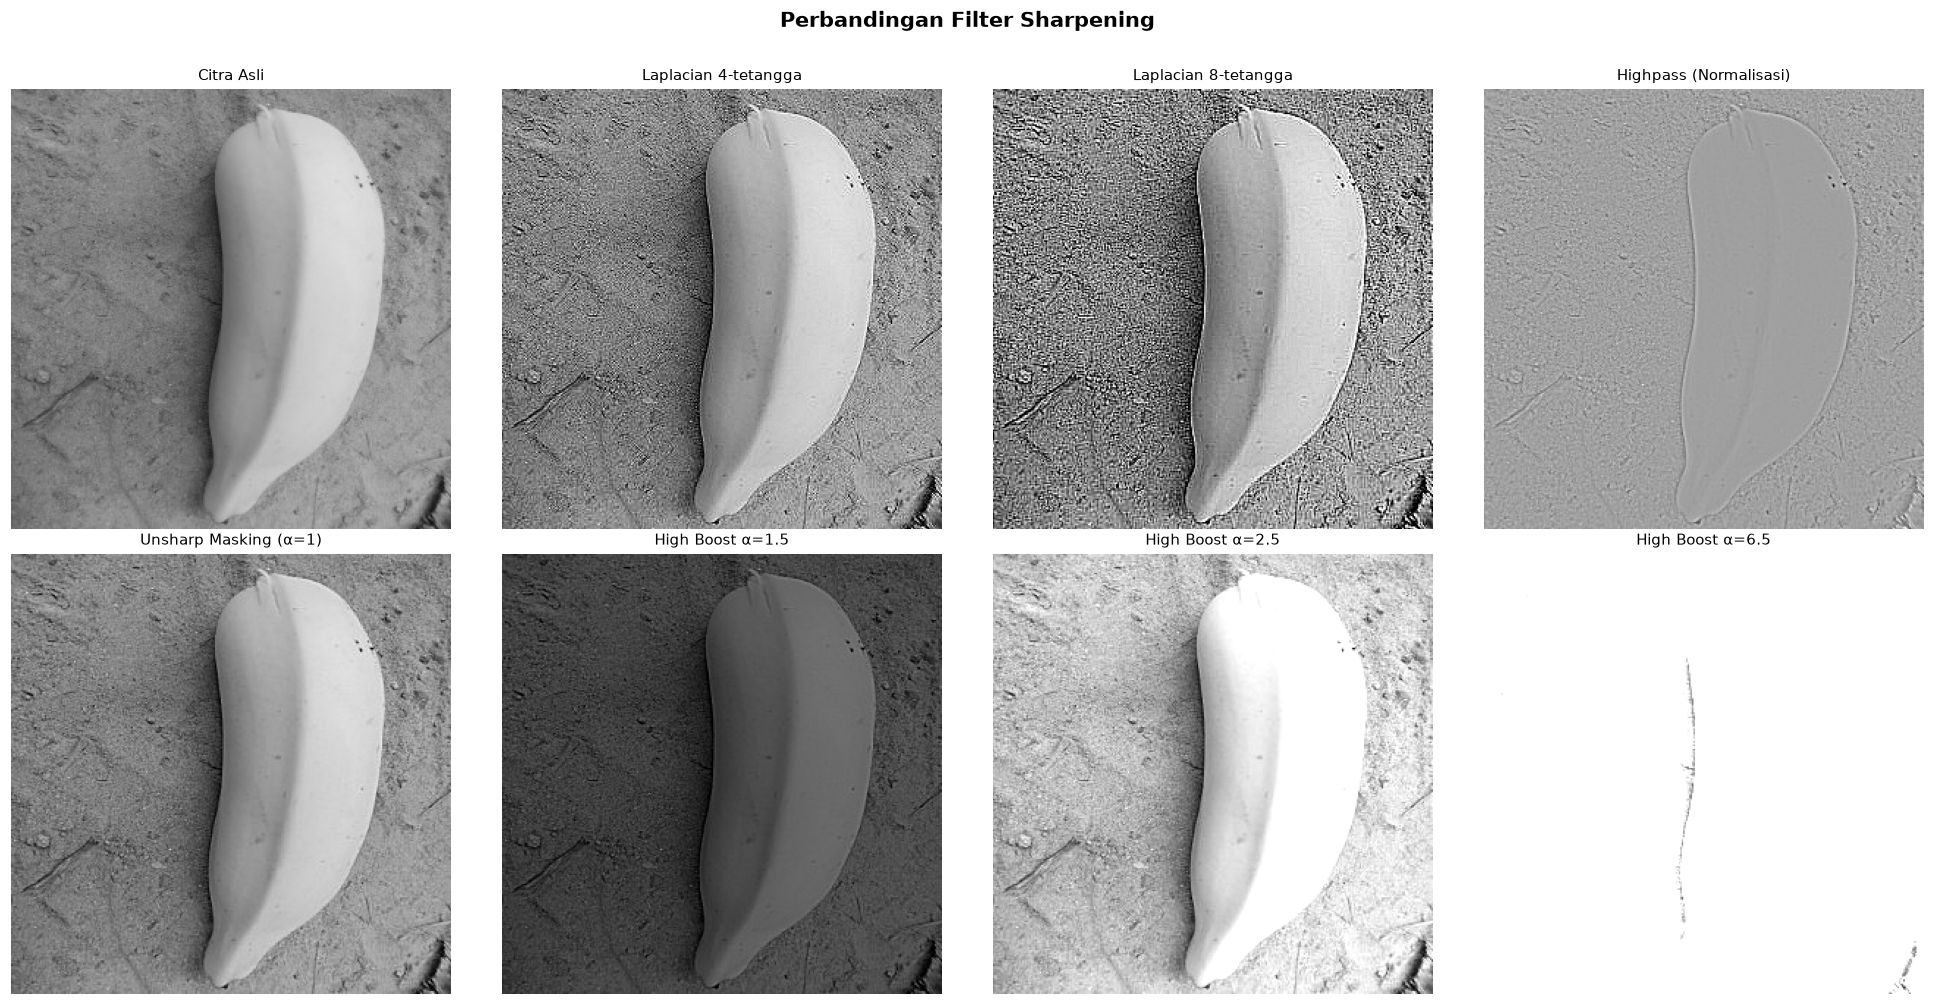

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Perbandingan Filter Sharpening', fontsize=14, fontweight='bold', y=1.01)

metode = [
    (img_gray,                     'Citra Asli'),
    (img_sharpened_aio_4nb,        'Laplacian 4-tetangga'),
    (img_sharpened_aio_8nb,        'Laplacian 8-tetangga'),
    (hp_vis,                       'Highpass (Normalisasi)'),
    (img_unsharp,                  'Unsharp Masking (α=1)'),
    (hasil_highboost[1.5],         'High Boost α=1.5'),
    (hasil_highboost[2.5],         'High Boost α=2.5'),
    (hasil_highboost[6.5],         'High Boost α=6.5'),
]

for ax, (img, title) in zip(axes.ravel(), metode):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('hasil_output/perbandingan_sharpening.png', dpi=200, bbox_inches='tight')
plt.show()


## Bagian 8 — Analisis Kuantitatif

Mengukur **sharpness** secara kuantitatif menggunakan **Laplacian variance** — semakin tinggi → semakin tajam.


In [15]:
def ukur_ketajaman(citra):
    """Laplacian variance sebagai ukuran ketajaman citra."""
    lap = cv2.Laplacian(citra, cv2.CV_64F)
    return lap.var()

hasil_uji = [
    ('Citra Asli',              img_gray),
    ('Laplacian 4-tetangga',    img_sharpened_aio_4nb),
    ('Laplacian 8-tetangga',    img_sharpened_aio_8nb),
    ('Unsharp Masking',         img_unsharp),
    ('High Boost α=1.5',        hasil_highboost[1.5]),
    ('High Boost α=2.5',        hasil_highboost[2.5]),
    ('High Boost α=6.5',        hasil_highboost[6.5]),
]

print(f"{'Metode':<28} {'Laplacian Var':>15} {'vs. Asli':>10}")
print('-' * 55)
lap_asli = ukur_ketajaman(img_gray)
for nama, hasil in hasil_uji:
    lap_var = ukur_ketajaman(hasil)
    ratio   = lap_var / lap_asli
    print(f"{nama:<28} {lap_var:>15.1f} {ratio:>10.2f}×")


Metode                         Laplacian Var   vs. Asli
-------------------------------------------------------
Citra Asli                             594.6       1.00×
Laplacian 4-tetangga                 19878.7      33.43×
Laplacian 8-tetangga                 46363.7      77.98×
Unsharp Masking                       2326.2       3.91×
High Boost α=1.5                      1288.1       2.17×
High Boost α=2.5                      3506.7       5.90×
High Boost α=6.5                       150.2       0.25×
